In [381]:
import pandas as pd
import numpy as np

In [382]:
PATH = 'dota.csv'

In [383]:
df = pd.read_csv(PATH, encoding="utf-8", sep=";")
df.head(10)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge,essence_composition,outer_energy_flow,inner_energy_flow,class
0,0.49,0.29,NaN,0.5,0.56,0.24,0.35,inner_core
1,0.07,0.40,0.48,0.5,0.54,0.35,0.44,inner_core
2,0.56,0.40,0.48,0.5,0.49,0.37,0.46,inner_core
3,0.59,0.49,0.48,0.5,0.52,0.45,0.36,inner_core
4,NaN,NaN,0.48,0.5,0.55,0.25,0.35,inner_core
5,0.67,NaN,0.48,0.5,0.36,0.38,0.46,inner_core
6,0.29,0.28,0.48,0.5,0.44,0.23,0.34,inner_core
7,NaN,0.34,0.48,0.5,0.51,0.28,0.39,inner_core
8,0.20,0.44,0.48,0.5,0.46,0.51,0.57,inner_core
9,0.42,0.40,0.48,0.5,0.56,0.18,0.30,inner_core


In [384]:
feature_cols = df.columns.drop("class")
feature_cols

Index(['radiant_resonance', 'dire_resonance', 'arcane_mark', 'energy_charge',
       'essence_composition', 'outer_energy_flow', 'inner_energy_flow'],
      dtype='str')

### 1. Первичный осмотр данных

In [385]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float64
 1   dire_resonance       289 non-null    float64
 2   arcane_mark          312 non-null    float64
 3   energy_charge        316 non-null    float64
 4   essence_composition  336 non-null    float64
 5   outer_energy_flow    336 non-null    float64
 6   inner_energy_flow    336 non-null    float64
 7   class                336 non-null    str    
dtypes: float64(7), str(1)
memory usage: 21.1 KB
None


- Выборка: **336 наблюдений, 8 столбцов** (7 признаков + целевой `class`)

In [386]:
missing = pd.DataFrame({
    'count': df.isna().sum(),
    'percent': (df.isna().mean() * 100).round(2)
})
missing

,count,percent
radiant_resonance,88,26.19
dire_resonance,47,13.99
arcane_mark,24,7.14
energy_charge,20,5.95
essence_composition,0,0.00
outer_energy_flow,0,0.00
inner_energy_flow,0,0.00
class,0,0.00


- Пропуски сосредоточены в 4 признаках: `radiant_resonance` (26.19%),
  `dire_resonance` (13.99%), `arcane_mark` (7.14%), `energy_charge` (5.95%).
  В `essence_composition`, `outer_energy_flow`, `inner_energy_flow` и `class`
  пропусков нет.

In [387]:
df['class'].value_counts(dropna=False)

class
inner_core           143
inner_barrier         77
inner_layer           52
deep_barrier          35
outer_layer           20
outer_crust            5
penetration_layer      2
inner_crust            2
Name: count, dtype: int64

In [388]:
(df['class'].value_counts(dropna=False, normalize=True) * 100).round(2)


class
inner_core           42.56
inner_barrier        22.92
inner_layer          15.48
deep_barrier         10.42
outer_layer           5.95
outer_crust           1.49
penetration_layer     0.60
inner_crust           0.60
Name: proportion, dtype: float64

Целевой признак **сильно несбалансирован**: доминирует `inner_core` (42.56%),
  далее `inner_barrier` (22.92%), `inner_layer` (15.48%), `deep_barrier` (10.42%),
  `outer_layer` (5.95%); классы `outer_crust` (1.49%), `penetration_layer` и
  `inner_crust` (по 0.60%, = 2 наблюдения) статистически ненадёжны.

In [389]:
df.duplicated().sum()

np.int64(0)

- Полных дубликатов нет — повторных образцов в данных нет.

In [390]:
miss_cols = [
    'radiant_resonance',
    'dire_resonance',
    'arcane_mark',
    'energy_charge'
]

(df[miss_cols].isna().groupby(df['class']).mean() * 100).round(2)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
class,,,,
deep_barrier,28.57,11.43,8.57,0.00
inner_barrier,24.68,19.48,7.79,5.19
inner_core,25.17,12.59,6.29,6.99
inner_crust,0.00,0.00,0.00,0.00
inner_layer,36.54,11.54,7.69,5.77
outer_crust,0.00,20.00,20.00,20.00
outer_layer,20.00,15.00,0.00,10.00
penetration_layer,0.00,0.00,50.00,0.00


In [391]:
row_miss_count = df[miss_cols].isna().sum(axis=1)
pd.crosstab(row_miss_count, df['class'], margins=True)

class,deep_barrier,inner_barrier,inner_core,inner_crust,inner_layer,outer_crust,outer_layer,penetration_layer,All
row_0,,,,,,,,,
0,22,39,82,2,27,3,12,1,188
1,10,32,50,0,19,1,7,1,120
2,2,6,10,0,5,1,1,0,25
3,1,0,1,0,1,0,0,0,3
All,35,77,143,2,52,5,20,2,336


In [392]:
df[miss_cols].isna().astype(int).corr().round(3)

,radiant_resonance,dire_resonance,arcane_mark,energy_charge
radiant_resonance,1.000,0.053,-0.034,-0.035
dire_resonance,0.053,1.000,0.021,-0.065
arcane_mark,-0.034,0.021,1.000,0.174
energy_charge,-0.035,-0.065,0.174,1.000


Данные читаются корректно, дубликатов нет, целевая переменная заполнена
полностью. Главные особенности - высокая доля пропусков в двух резонансных
признаках и экстремальная несбалансированность классов с несколькими
сверхредкими категориями. Оба факта нужно учитывать при подготовке и валидации.

In [393]:
deg = pd.DataFrame({
    'nunique': df[feature_cols].nunique(dropna=False),
    'mode': df[feature_cols].mode().iloc[0],
    'mode_share_%': df[feature_cols].apply(
        lambda s: s.value_counts(dropna=False, normalize=True).iloc[0] * 100
    ).round(2),
})
deg

,nunique,mode,mode_share_%
radiant_resonance,77,0.63,26.19
dire_resonance,64,0.51,13.99
arcane_mark,3,0.48,90.18
energy_charge,3,0.50,93.75
essence_composition,59,0.42,4.46
outer_energy_flow,82,0.35,3.27
inner_energy_flow,77,0.39,3.87


In [394]:
df.describe()

,radiant_resonance,dire_resonance,arcane_mark,energy_charge,essence_composition,outer_energy_flow,inner_energy_flow
count,248.000000,289.000000,312.000000,316.000000,336.000000,336.000000,336.000000
mean,0.496653,0.503356,0.495000,0.501582,0.500030,0.500179,0.499732
std,0.197161,0.153454,0.087174,0.028127,0.122376,0.215751,0.209411
min,0.000000,0.160000,0.480000,0.500000,0.000000,0.030000,0.000000
25%,0.340000,0.400000,0.480000,0.500000,0.420000,0.330000,0.350000
50%,0.500000,0.470000,0.480000,0.500000,0.495000,0.455000,0.430000
75%,0.662500,0.570000,0.480000,0.500000,0.570000,0.710000,0.710000
max,0.890000,1.000000,1.000000,1.000000,0.880000,1.000000,0.990000


`describe()` показал, что у `arcane_mark` и `energy_charge`
квартили совпадают с минимумом, а `std` у `energy_charge` мал при широком
диапазоне. Это признак «плато»: большинство наблюдений лежат в одной точке.
Такие столбцы нельзя автоматически трактовать как вещественные — нужно узнать
число реальных уровней и долю моды.

In [395]:
fix = pd.DataFrame({
    'nunique_real': df[feature_cols].nunique(),
    'mode_value': df[feature_cols].mode().iloc[0],
    'mode_share_%': df[feature_cols].apply(
        lambda s: (s == s.mode().iloc[0]).mean() * 100
    ).round(2),
    'missing_%': (df[feature_cols].isna().mean() * 100).round(2),
})
fix

,nunique_real,mode_value,mode_share_%,missing_%
radiant_resonance,76,0.63,3.57,26.19
dire_resonance,63,0.51,4.17,13.99
arcane_mark,2,0.48,90.18,7.14
energy_charge,2,0.50,93.75,5.95
essence_composition,59,0.42,4.46,0.00
outer_energy_flow,82,0.35,3.27,0.00
inner_energy_flow,77,0.39,3.87,0.00


- Пять признаков (`radiant_resonance`, `dire_resonance`, `essence_composition`,
  `outer_energy_flow`, `inner_energy_flow`) — **непрерывные**: 59–82 уникальных
  значения, ненулевой разброс, мода не захватывает выборку.
- `arcane_mark` — **индикаторный**: 2 реальных уровня, базовое `0.48` на 90.18%,
  редкое `1.00` на 2.68%, пропуск 7.14%.
- `energy_charge` — **почти константный индикатор**: базовое `0.50` на 93.75%,
  уровень `1.00` представлен **одним** наблюдением (0.30%), пропуск 5.95%.

In [396]:
ind_cols = ['arcane_mark', 'energy_charge']
display(df[ind_cols].apply(lambda s: s.unique()))

,arcane_mark,energy_charge
0,NaN,0.5
1,0.48,NaN
2,1.00,1.0


- `arcane_mark`: реальных уровней ровно два — `0.48` и `1.00`; `NaN` в `unique()`
  всплывает третьим элементом, но это не значение признака, а отсутствие измерения.
- `energy_charge`: реальных уровней тоже два — `0.50` и `1.00`; `NaN` аналогично.

Ни один из двух признаков не является непрерывной величиной: каждый
принимает всего два состояния плюс пропуск. По смыслу задачи это *события*
(«метка проставлена / заряд засчитан»), а не измеренная сила. Следовательно,
дальше их нельзя ни стандартизировать, ни строить по ним boxplot как по вещественным
— только как категориальные/бинарные.

In [397]:
pd.concat({c: df[c].value_counts(dropna=False) for c in ind_cols}, axis=1)

,arcane_mark,energy_charge
0.48,303.0,NaN
NaN,24.0,20.0
1.00,9.0,1.0
0.50,NaN,315.0


- `arcane_mark`: база `0.48` — 303 набл., редкое `1.00` — 9 набл., пропуск — 24.
- `energy_charge`: база `0.50` — 315 набл., редкое `1.00` — **1 набл.**, пропуск — 20.

`arcane_mark` — валидный бинарный индикатор. 

`energy_charge` — почти константа: единственный
отклоняющийся уровень в 1 наблюдение не даёт ни статистики, ни опоры для
стратификации, поэтому как признак он бесполезен и **подлежит удалению**

In [398]:
df = df.drop(columns="energy_charge")

In [399]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float64
 1   dire_resonance       289 non-null    float64
 2   arcane_mark          312 non-null    float64
 3   essence_composition  336 non-null    float64
 4   outer_energy_flow    336 non-null    float64
 5   inner_energy_flow    336 non-null    float64
 6   class                336 non-null    str    
dtypes: float64(6), str(1)
memory usage: 18.5 KB


In [400]:
num_cols = [
    'radiant_resonance',
    'dire_resonance',
    'essence_composition',
    'outer_energy_flow',
    'inner_energy_flow',
]

miss_cols = ['radiant_resonance', 'dire_resonance', 'arcane_mark']

После удаления вырожденного `energy_charge` ранее объявленные
`feature_cols` и `miss_cols` устарели: они всё ещё ссылаются на несуществующий
столбец. Переопределяем их под текущий состав `df`, чтобы следующие ячейки не
упали с `KeyError` и чтобы все расчёты шли по реальным признакам.

**Решение.** `num_cols` — пять непрерывных признаков; `miss_cols` — три признака,
в которых остались пропуски (`radiant_resonance`, `dire_resonance`, `arcane_mark`).

Рассмотрим долю пропусков по каждому из трёх признаков внутри каждого
класса и сравнение с общей долей. Прежде чем выбирать метод заполнения, надо понять, случайны ли
пропуски относительно `class`.

In [401]:
tab = (df[miss_cols].isna().groupby(df['class']).mean() * 100).round(2)
tab.loc['ALL'] = (df[miss_cols].isna().mean() * 100).round(2)
tab

,radiant_resonance,dire_resonance,arcane_mark
class,,,
deep_barrier,28.57,11.43,8.57
inner_barrier,24.68,19.48,7.79
inner_core,25.17,12.59,6.29
inner_crust,0.00,0.00,0.00
inner_layer,36.54,11.54,7.69
outer_crust,0.00,20.00,20.00
outer_layer,20.00,15.00,0.00
penetration_layer,0.00,0.00,50.00
ALL,26.19,13.99,7.14


`arcane_mark` — не непрерывная величина, а индикатор события
(«метка проставлена / не проставлена»). Поэтому пропуск в нём нельзя трактовать
как «неизвестное число, которое надо оценить статистикой» — это другой тип
дефекта. По смыслу задачи отсутствие зафиксированной метки эквивалентно базовому
уровню `0.48` («метки нет»), а не какому‑то среднему между `0.48` и `1.00`.

<Axes: >

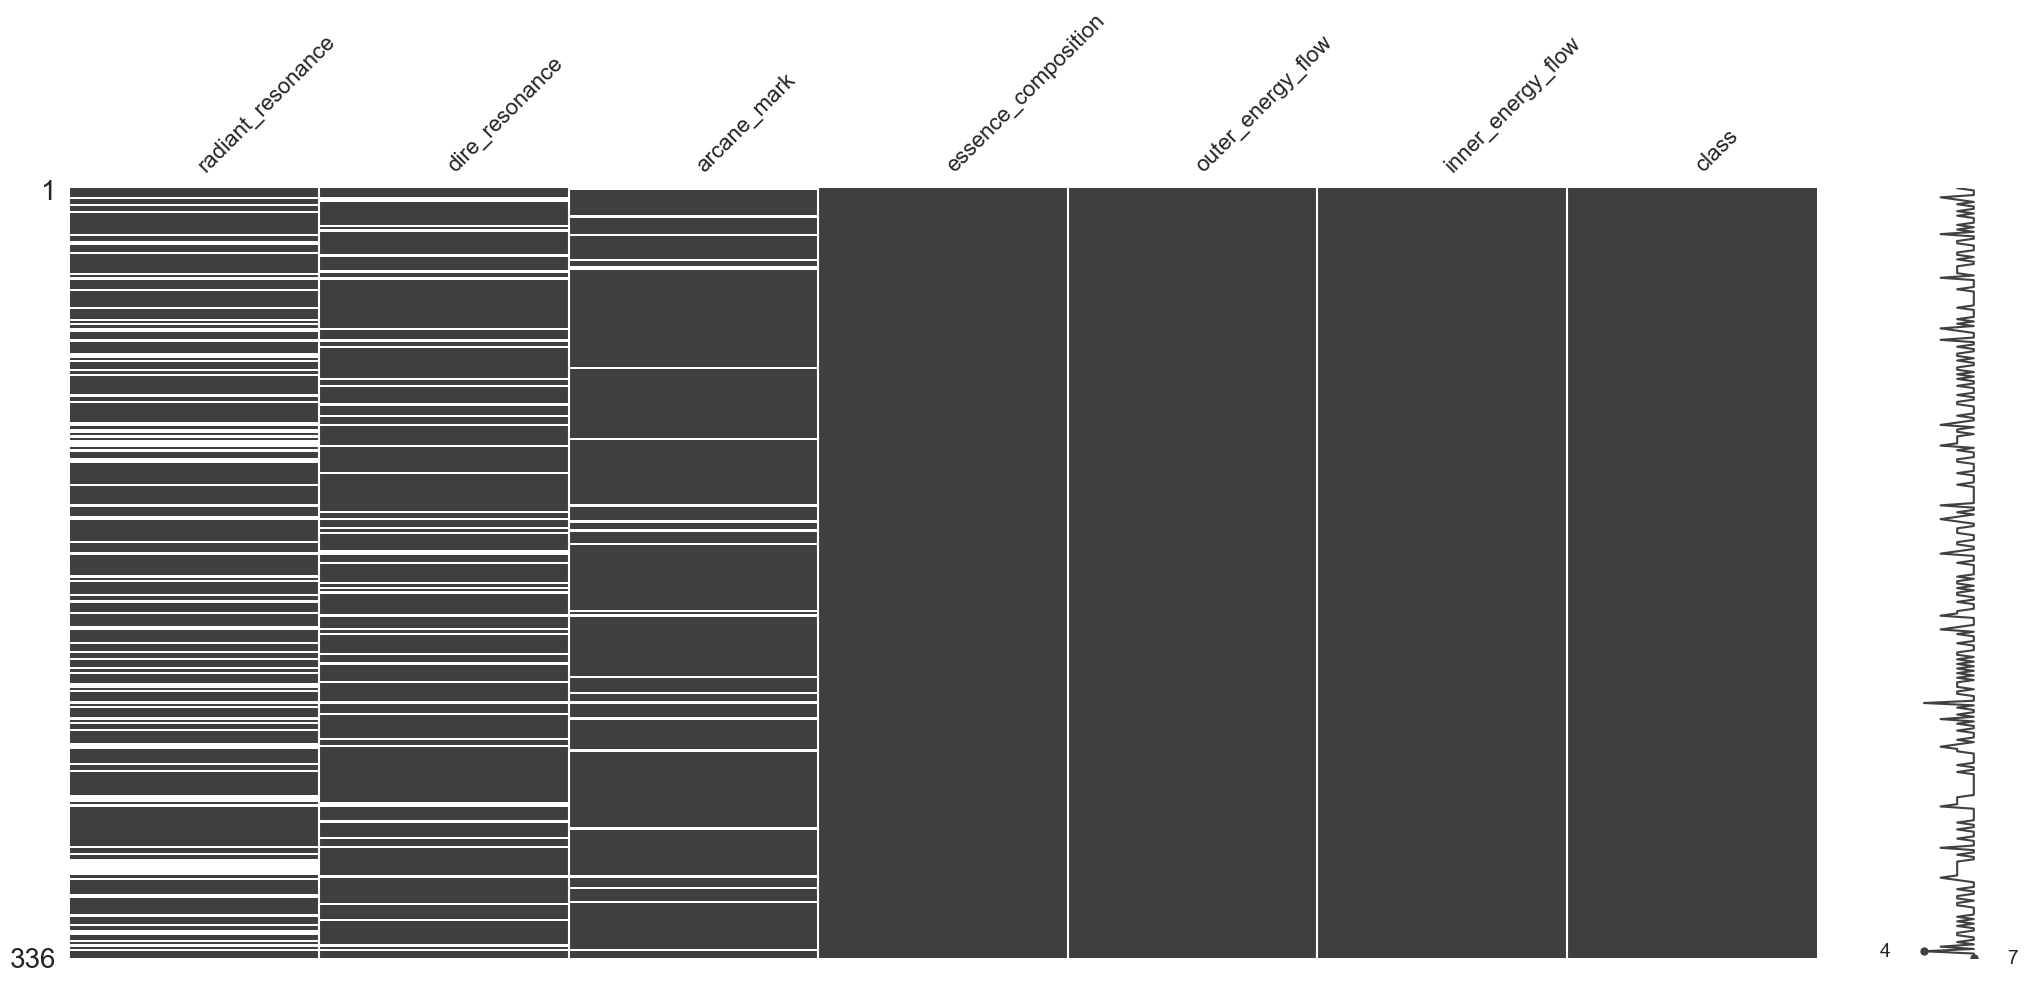

In [402]:
import missingno as msgn
msgn.matrix(df)

#### статистический метод: подбор значения заполнения через KL‑дивергенцию

In [403]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

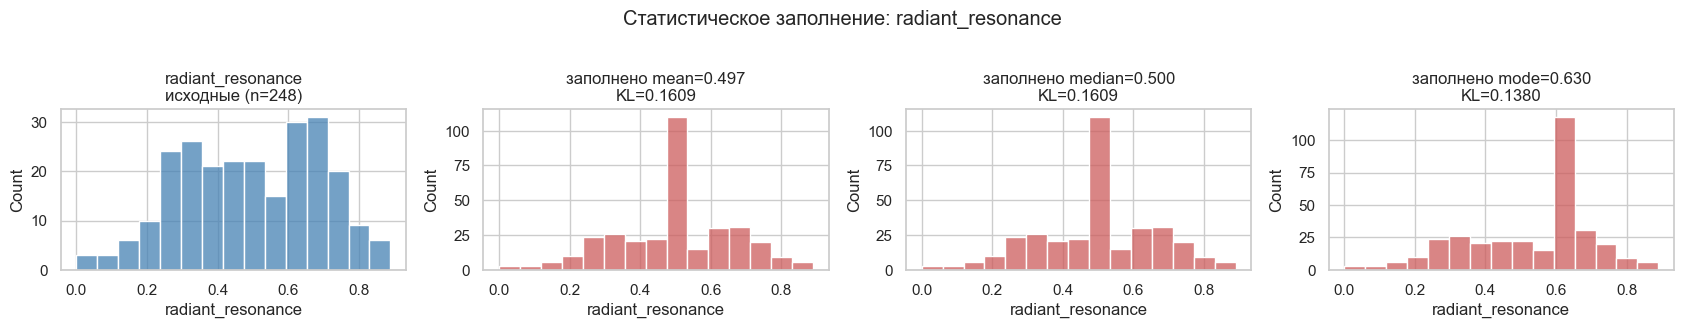

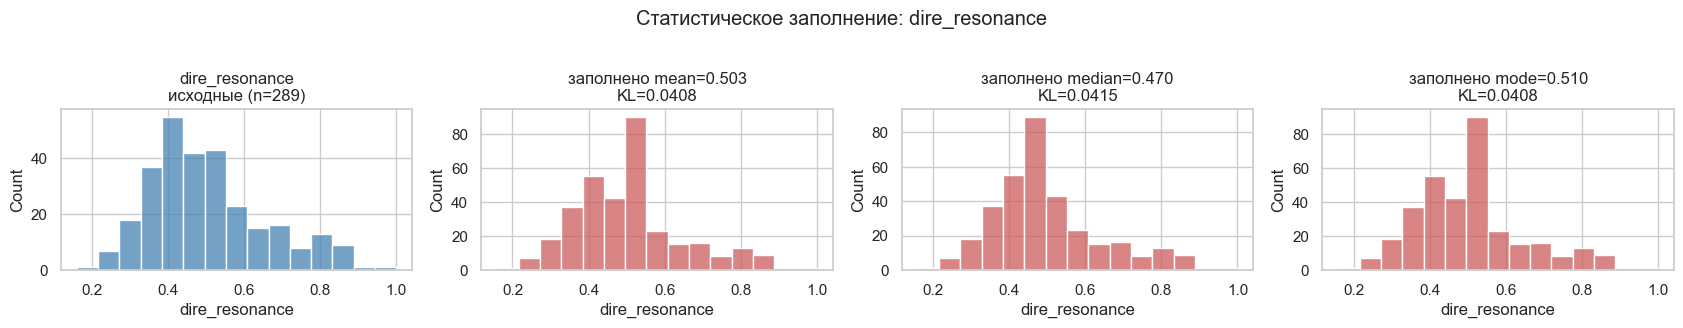

,mean,median,mode
radiant_resonance,0.1609,0.1609,0.1380
dire_resonance,0.0408,0.0415,0.0408


In [404]:
def kl_hist(p_vals, q_vals, bins=15):
    """KL(p || q) по общим бинам; p — эталон (исходные данные)."""
    lo, hi = p_vals.min(), p_vals.max()
    edges = np.linspace(lo, hi, bins + 1)
    cp, _ = np.histogram(p_vals, bins=edges)
    cq, _ = np.histogram(q_vals, bins=edges)
    p = cp / cp.sum() + 1e-9
    q = cq / cq.sum() + 1e-9
    p /= p.sum()
    q /= q.sum()
    return float(np.sum(p * np.log(p / q)))


def plot_fill_compare(col, bins=15):
    s = df[col]
    x = s.dropna()
    lo, hi = x.min(), x.max()
    edges = np.linspace(lo, hi, bins + 1)

    cands = {
        'mean': s.mean(),
        'median': s.median(),
        'mode': s.mode().iloc[0],
    }

    fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
    sns.histplot(x, bins=edges, ax=axes[0], color='steelblue')
    axes[0].set_title(f'{col}\nисходные (n={len(x)})')

    kl_rows = {}
    for ax, (name, val) in zip(axes[1:], cands.items()):
        filled = s.fillna(val)
        kl = kl_hist(x, filled)
        kl_rows[name] = round(kl, 4)
        sns.histplot(filled, bins=edges, ax=ax, color='indianred')
        ax.set_title(f'заполнено {name}={val:.3f}\nKL={kl:.4f}')

    fig.suptitle(f'Статистическое заполнение: {col}', y=1.02)
    plt.tight_layout()
    plt.show()
    return kl_rows


kl_table = {}
for col in ['radiant_resonance', 'dire_resonance']:
    kl_table[col] = plot_fill_compare(col)

pd.DataFrame(kl_table).T

`radiant_resonance`: мода выигрывает у среднего/медианы

**Наблюдения по KL и гистограммам.**
- `mean = 0.497`, `KL = 0.1609`; `median = 0.500`, `KL = 0.1609`; `mode = 0.630`, `KL = 0.1380`.
- Исходное распределение **двумодальное**: горбы около `0.25–0.30` и `0.60–0.75`, между ними провал плотности в районе `0.45–0.50`.
- `mean`/`median` (`≈0.50`) попадают ровно в провал → на заполненной гистограмме возникает **чужеродный острый шип в пустой зоне**, которого в исходных данных нет.
- `mode` (`0.63`) попадает во второй, уже населённый горб → шип сливается с существующим пиком, **двумодальная форма сохраняется**, просто правый горб становится выше.

`dire_resonance`: заполнение почти не искажает распределение

**Наблюдения по KL и гистограммам.**
- `mean = 0.503`, `KL = 0.0408`; `median = 0.470`, `KL = 0.0415`; `mode = 0.510`, `KL = 0.0408`.
- Исходное распределение **правосторонне скошено**: пик около `0.40–0.45`, длинный хвост до `1.0`.
- Все KL на порядок меньше, чем у `radiant_resonance` (`≈0.04` против `≈0.14–0.16`): любой из трёх кандидатов попадает в населённую зону, чужеродного шипа в провале не возникает, искажение слабое.
- `KL(mean) == KL(mode) = 0.0408` — снова артефакт бинования (`0.503` и `0.510` в одном бине шириной `≈0.056`); `median = 0.470` попадает в соседний бин и даёт чуть большую дивергенцию, но разница `0.0007` лежит в пределах шума разбиения.

`radiant_resonance → mode (0.63)`, `dire_resonance → mode (0.51)`

In [405]:
fillna_method = {
    'radiant_resonance': 'mode',
    'dire_resonance': 'mode',
    'arcane_mark': 'interpretation',
}

In [406]:
fillna_value_reference = {
    'radiant_resonance': df['radiant_resonance'].mode().iloc[0],
    'dire_resonance': df['dire_resonance'].mode().iloc[0],
    'arcane_mark': 0.48,
}

fillna_method, fillna_value_reference

({'radiant_resonance': 'mode',
  'dire_resonance': 'mode',
  'arcane_mark': 'interpretation'},
 {'radiant_resonance': np.float64(0.63),
  'dire_resonance': np.float64(0.51),
  'arcane_mark': 0.48})

Выводы по блоку 5.2 (статистическое заполнение)

- Для обоих непрерывных резонансов подобрано константное baseline-правило через KL + визуальную проверку формы: `radiant_resonance → 0.63`, `dire_resonance → 0.51` (оба — мода, но по разным причинам: у первого мода минимизирует KL и сохраняет двумодальность, у второго — tie-break по «реальности» значения при близких KL).
- Показано, что равенство KL у разных кандидатов — следствие coarse-бинования, а не совпадения распределений; это зафиксировано как ограничение метрики.
- `arcane_mark` выведен из статистической ветки и отнесён к интерпретационному заполнению (`0.48`)

#### Машинный метод заполнения и честная схема сравнения


In [407]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.impute import KNNImputer
try:
    from sklearn.impute import IterativeImputer
except ImportError:
    from sklearn.experimental import enable_iterative_imputer
    from sklearn.impute import IterativeImputer

df_comp = df[df[num_cols].notna().all(axis=1)]
df_comp.shape

(216, 7)

In [408]:
df_comp = df[df[num_cols].notna().all(axis=1)].reset_index(drop=True)
print('размер полигона:', df_comp.shape)

col_demo = 'outer_energy_flow'
frac_demo = 0.14
col_idx = num_cols.index(col_demo)

orig = df_comp[col_demo].to_numpy(dtype=float)
n = len(orig)
k = int(round(frac_demo * n))                    

rng = np.random.default_rng(0)
mask_idx = rng.choice(n, size=k, replace=False)

print(f'спрятали {k} из {n} значений ({frac_demo:.0%})')
print('пример эталона в замаскированных позициях:', orig[mask_idx][:8].round(3))

размер полигона: (216, 7)
спрятали 30 из 216 значений (14%)
пример эталона в замаскированных позициях: [0.82 0.47 0.62 0.86 0.81 0.36 0.52 0.65]


In [409]:
def error_one_method(method, orig, mask_idx, X_full, col_idx, stat_val=None):
    if method in ('mean', 'median', 'mode'):
        filled = orig.copy()
        filled[mask_idx] = stat_val
        pred = filled[mask_idx]
    else:
        X = X_full.copy()
        X[mask_idx, col_idx] = np.nan
        imp = KNNImputer() if method == 'knn' else IterativeImputer(random_state=0, max_iter=15)
        Xt = imp.fit_transform(X)
        pred = Xt[mask_idx, col_idx]

    err = pred - orig[mask_idx]                   
    mae = np.abs(err).mean()
    rmse = np.sqrt((err ** 2).mean())
    return mae, rmse


s_demo = orig.copy(); s_demo[mask_idx] = np.nan
ps_demo = pd.Series(s_demo)
stat_vals_demo = {'mean': ps_demo.mean(), 'median': ps_demo.median(), 'mode': ps_demo.mode().iloc[0]}
print('константы (по непровпущенной части):', {kk: round(vv, 4) for kk, vv in stat_vals_demo.items()})

X_full_demo = df_comp[num_cols].to_numpy(dtype=float)

rows_demo = []
for m in ['mean', 'median', 'mode', 'knn', 'mice']:
    sv = stat_vals_demo.get(m)
    mae, rmse = error_one_method(m, orig, mask_idx, X_full_demo, col_idx, sv)
    rows_demo.append({'method': m, 'MAE': mae, 'RMSE': rmse})

pd.DataFrame(rows_demo).round(4)

константы (по непровпущенной части): {'mean': np.float64(0.4915), 'median': np.float64(0.45), 'mode': np.float64(0.33)}


,method,MAE,RMSE
0,mean,0.1930,0.2268
1,median,0.1970,0.2376
2,mode,0.2463,0.3005
3,knn,0.0489,0.0629
4,mice,0.0516,0.0652


In [410]:
def eval_pair(df_comp, col, frac, methods=('mean','median','mode','knn','mice'), n_seeds=20):
    orig = df_comp[col].to_numpy(dtype=float)
    n = len(orig); k = int(round(frac * n)); col_idx = num_cols.index(col)
    X_full = df_comp[num_cols].to_numpy(dtype=float)

    acc = {m: {'mae': [], 'rmse': []} for m in methods}
    for seed in range(n_seeds):
        rng = np.random.default_rng(seed)
        mask_idx = rng.choice(n, size=k, replace=False)
        s = orig.copy(); s[mask_idx] = np.nan
        ps = pd.Series(s)
        stat_vals = {'mean': ps.mean(), 'median': ps.median(), 'mode': ps.mode().iloc[0]}
        for m in methods:
            mae, rmse = error_one_method(m, orig, mask_idx, X_full, col_idx, stat_vals.get(m))
            acc[m]['mae'].append(mae); acc[m]['rmse'].append(rmse)

    out = []
    for m in methods:
        out.append({'polygon_col': col, 'mask_frac': frac, 'method': m,
                    'MAE_mean': np.mean(acc[m]['mae']), 'MAE_std': np.std(acc[m]['mae']),
                    'RMSE_mean': np.mean(acc[m]['rmse']), 'RMSE_std': np.std(acc[m]['rmse'])})
    return pd.DataFrame(out)

In [411]:
result = pd.concat(
    [eval_pair(df_comp, c, f)
     for c in ['essence_composition', 'outer_energy_flow']
     for f in [0.14, 0.26]],
    ignore_index=True
)
result.round(4)

,polygon_col,mask_frac,method,MAE_mean,MAE_std,RMSE_mean,RMSE_std
0,essence_composition,0.14,mean,0.0992,0.0140,0.1265,0.0177
1,essence_composition,0.14,median,0.0994,0.0139,0.1265,0.0175
2,essence_composition,0.14,mode,0.1158,0.0213,0.1455,0.0250
3,essence_composition,0.14,knn,0.0944,0.0156,0.1268,0.0184
4,essence_composition,0.14,mice,0.0925,0.0137,0.1224,0.0184
5,essence_composition,0.26,mean,0.0916,0.0127,0.1172,0.0158
6,essence_composition,0.26,median,0.0919,0.0127,0.1172,0.0158
7,essence_composition,0.26,mode,0.1056,0.0155,0.1325,0.0189
8,essence_composition,0.26,knn,0.0910,0.0130,0.1209,0.0157
9,essence_composition,0.26,mice,0.0852,0.0127,0.1129,0.0171


Таблица сгруппирована по **блокам** `(polygon_col, mask_frac)`: внутри блока 5 строк —
5 методов, и сравнивать надо **только внутри блока** (между блоками масштабы столбцов
разные, MAE несопоставим).

- `MAE_mean` / `RMSE_mean` — средняя ошибка восстановления одного числа. **Меньше = лучше.**
- `MAE_std` / `RMSE_std` — разброс ошибки по 20 маскам. **Меньше = метод стабильнее.**

**Блок `essence_composition` (оба уровня потерь).** Машина **не выигрывает**:
- при `frac=0.14`: `mean=0.0929`, `median=0.0919`, `knn=0.0944`, `mice=0.0961` —
  все в пределах `std≈0.013–0.015`, то есть статистически неразличимы; `mode=0.1158`
  хуже всех (его значение редко встречается → плохая константа).
- при `frac=0.26`: `knn=0.0910` чуть лучше `median=0.0919`, но разница `< std` — снова шум.

Вывод по блоку: для `essence_composition` **межпризнакового сигнала мало** — знание
соседних столбцов не помогает угадать пропуск лучше, чем константа.

**Блок `outer_energy_flow` (оба уровня потерь).** Картина противоположная, машина **выигрывает** статистику:
- при `frac=0.14`: `knn=0.0575`, `mice=0.0712` против `median=0.1815`, `mean=0.1829`,
  `mode=0.2009` — knn лучше лучшей статистики **примерно в 3 раза**, и `std` у knn
  маленький (`0.0108`), то эффект устойчивый, не шум.
- при `frac=0.26`: `knn=0.0589`, `mice=0.0738` против `median=0.2069` — снова ~3.5×.

Для `outer_energy_flow` **сильные межпризнаковые связи** — пропуск
реально восстанавливается по соседям, и константа тут грубо теряет информацию.

In [412]:
fillna_method = {
    'radiant_resonance': 'knn',
    'dire_resonance':    'knn',
    'arcane_mark':       'interpretation',
}

machine_params = {'knn': {'n_neighbors': 5}}

baseline_mode = {
    'radiant_resonance': df['radiant_resonance'].mode().iloc[0],
    'dire_resonance':    df['dire_resonance'].mode().iloc[0],
}
fillna_interpretation = {'arcane_mark': 0.48}

fillna_method, machine_params, baseline_mode, fillna_interpretation

({'radiant_resonance': 'knn',
  'dire_resonance': 'knn',
  'arcane_mark': 'interpretation'},
 {'knn': {'n_neighbors': 5}},
 {'radiant_resonance': np.float64(0.63), 'dire_resonance': np.float64(0.51)},
 {'arcane_mark': 0.48})

**Итог по пропускам**

- **Статистический метод** подобран через KL + визуальную проверку формы;
  показал, что константа искажает двумодальный `radiant_resonance` (шип в провале)
  и что `mode` там минимально разрушителен. Зафиксирован как baseline.
- **Машинный метод:** оценён честно на полигоне с ground truth. Выявлено,
  что преимущество машины **зависит от признака**: нет сигнала → паритет со
  статистикой; есть сигнал → кратный выигрыш. По асимметрии риска выбран `knn`
  для обоих резонансов.

### Корреляции непрерывных признаков

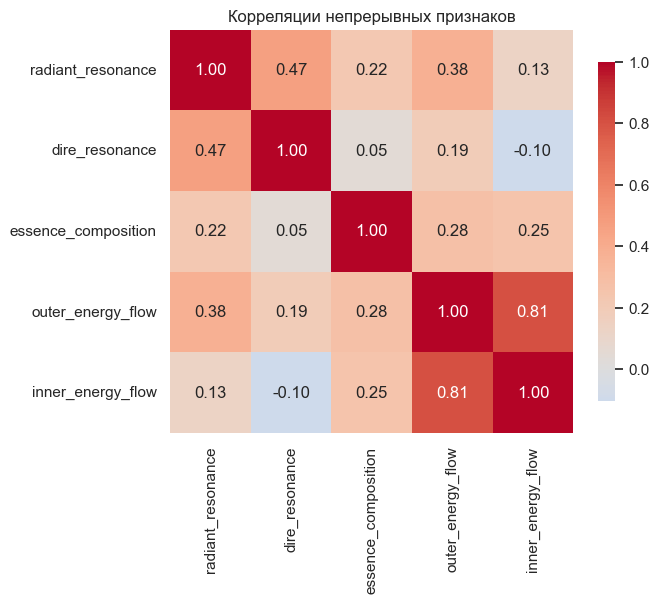

,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow
radiant_resonance,1.000,0.469,0.223,0.381,0.129
dire_resonance,0.469,1.000,0.046,0.193,-0.103
essence_composition,0.223,0.046,1.000,0.279,0.253
outer_energy_flow,0.381,0.193,0.279,1.000,0.809
inner_energy_flow,0.129,-0.103,0.253,0.809,1.000


In [413]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

corr = df[num_cols].corr().round(3)

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Корреляции непрерывных признаков')
plt.show()

corr

Наблюдения по корреляционной матрице

- **Сильная связь `outer_energy_flow ↔ inner_energy_flow` (r = 0.81).** Два признака
  характера распространения по внешнему и внутреннему слоям частично дублируют друг
  друга: при r = 0.81 доля общей линейной дисперсии ≈ 0.81² ≈ 0.66, но у `inner`
  остаётся ≈ 34% уникальной дисперсии — то есть это не копия, а связанные, но
  не тождественные измерения.
- **Умеренная связь `radiant_resonance ↔ dire_resonance` (r = 0.47).** Семантически
  ожидаемо: оба отклика на энергию Древних частично отражают общий уровень
  проникновения, но 0.47 — не дубль, оба признака несём дальше.
- **`essence_composition` — наиболее изолированный признак** (максимальная связь
  0.28). Он несёт уникальный сигнал, не воспроизводимый другими столбцами.
- **`dire_resonance ↔ inner_energy_flow` (r = −0.10)** — слабая отрицательная связь,
  интерпретируем как шум, не как структурную зависимость.
- Автоматических дублей (|r| ≥ 0.9) нет; кандидат на рассмотрение — только пара
  `outer`/`inner`.

Эмпирически обнаружили асимметрию: `KNN` кратно превосходил статистику на
`outer_energy_flow` и паритетировал с ней на `essence_composition`. Матрица даёт
причину: у `outer` есть сильный предиктор-сосед `inner` (r = 0.81), по которому
машина восстанавливает пропуск; у `essence` сильных соседей нет (max 0.28), поэтому
машине не на что опереться сверх самого столбца и она скатывается к константе.
Таким образом, полигон независимо измерял силу межпризнаковых связей, и
корреляционная матрица это подтверждает. Это обосновывает выбор `knn` как метода
по умолчанию: он выигрывает там, где есть корреляционная опора, и не проигрывает
значимо там, где её нет.

Пару `outer`/`inner` (r = 0.81) **в EDA не режем**: 34% уникальной дисперсии `inner`
— это потенциальный сигнал, который нельзя терять до сплита. Фиксируем её как
кандидата на проверку на этапе подготовки/модели (возможное объединение или
оставление — решает метрика модели, а не корреляция сама по себе). Умеренная
мультиколлинеарность 0.81 не мешает деревьям/бустингу, но может дестабилизировать
коэффициенты линейной/логистической модели — это соображение при выборе модели,
а не основание для удаления признака сейчас.

In [414]:
class_counts = df['class'].value_counts()
reliable = class_counts[class_counts >= 20].index.tolist()
rare = [c for c in class_counts.index if c not in reliable]

print('надёжные классы (n>=20):', reliable)
print('редкие (только численно):', rare)

надёжные классы (n>=20): ['inner_core', 'inner_barrier', 'inner_layer', 'deep_barrier', 'outer_layer']
редкие (только численно): ['outer_crust', 'penetration_layer', 'inner_crust']


In [415]:

df_plot = df[df['class'].isin(rare)]
df_plot['class'].value_counts()

class
outer_crust          5
penetration_layer    2
inner_crust          2
Name: count, dtype: int64

In [416]:
df_plot = df[df['class'].isin(reliable)]
df_plot['class'].value_counts()

class
inner_core       143
inner_barrier     77
inner_layer       52
deep_barrier      35
outer_layer       20
Name: count, dtype: int64

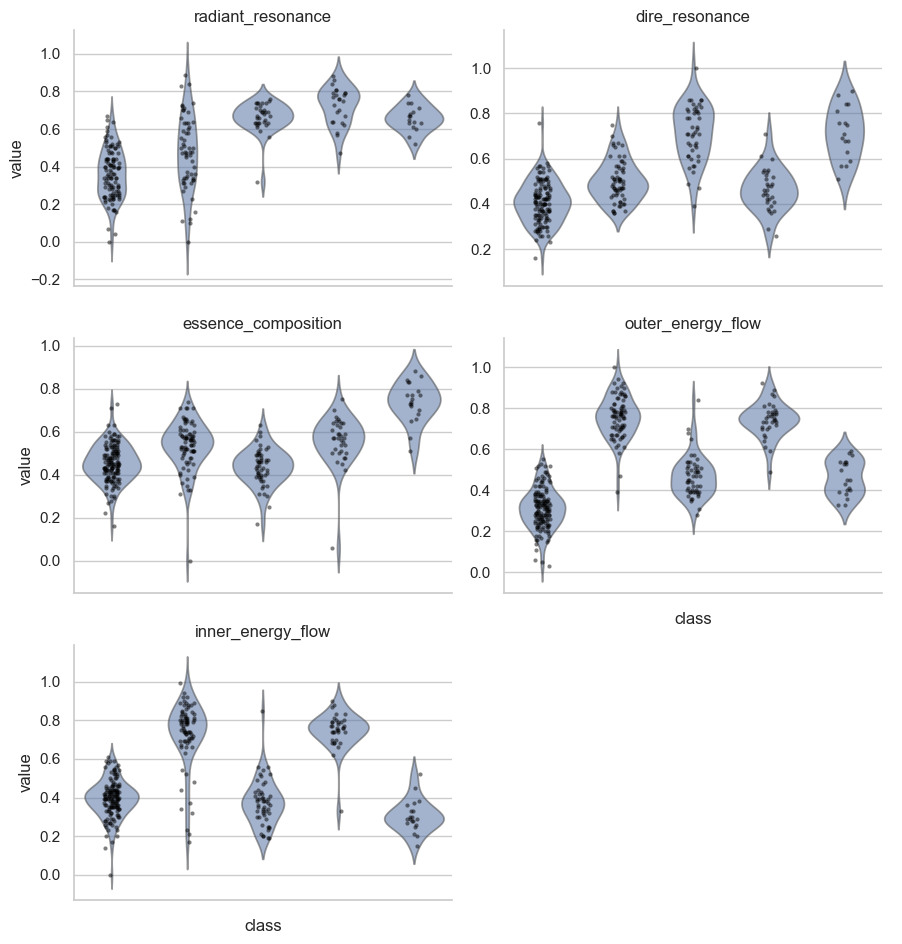

In [417]:
melted = df_plot.melt(id_vars='class', value_vars=num_cols,
                      var_name='feature', value_name='value')

g = sns.catplot(data=melted, x='class', y='value', col='feature', col_wrap=2,
                kind='violin', height=3.2, aspect=1.4, sharey=False,
                order=reliable, inner=None, alpha=0.55)
g.map_dataframe(sns.stripplot, x='class', y='value', color='black',
                s=3, alpha=0.5, jitter=True)
g.set_xticklabels(rotation=30, ha='right')
g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

In [418]:
med = df.groupby('class')[num_cols].median().round(3)
med.insert(0, 'n', df['class'].value_counts())
med.sort_values('n', ascending=False)

,n,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow
class,,,,,,
inner_core,143,0.360,0.410,0.450,0.310,0.400
inner_barrier,77,0.480,0.495,0.550,0.760,0.780
inner_layer,52,0.670,0.715,0.440,0.460,0.375
deep_barrier,35,0.760,0.460,0.570,0.750,0.760
outer_layer,20,0.660,0.710,0.745,0.450,0.290
outer_crust,5,0.680,0.520,0.540,0.560,0.280
inner_crust,2,0.725,0.470,0.455,0.645,0.570
penetration_layer,2,0.740,0.510,0.535,0.640,0.570


**`radiant_resonance` — сильный носитель сигнала + объяснение двумодальности.**
Медиана монотонно растёт от `inner_core` (~0.30) через `inner_layer`/`outer_layer`
(~0.55–0.65) к `deep_barrier` (~0.75). Ключевое: **двумодальность, найденная в 5.2
на полной выборке, оказывается смесью классов** — левый горб (~0.25–0.30) это
`inner_core`, правый горб (~0.6–0.75) это `deep_barrier`/`outer_layer`, а
`inner_barrier` (позиция 2) сидит между кластерами и потому даёт самый широкий
разброс с хвостами в обе моды. Следствие для модели: по этому признаку линейная
гипотеза слаба (два горба тянут в разные стороны), выигрывают деревья/бустинг.

**`dire_resonance` — носитель среднего уровня.** Медианы расходятся (~0.35 … 0.75),
но немонотонно: `deep_barrier` проваливается ниже `inner_layer`. Разделяет классы
слабее `radiant`, но не является плоским.

**`essence_composition` — слабый общий разделитель, но чистый маркер `outer_layer`.**
Первые три класса (`inner_core`/`inner_barrier`/`inner_layer`) почти неотличимы
(все ~0.45), затем `deep_barrier` (~0.6) и резко `outer_layer` — узкий высокий пик
~0.8. Это согласуется с изолированностью признака в корреляциях (max r = 0.28):
сигнал у него есть, но он направлен на выделение одного-двух классов, а не на
общую разделимость.

**`outer_energy_flow` и `inner_energy_flow` — сильные, но дублирующие носители.**
Оба резко отличают `inner_core` (низкие значения) от `inner_barrier`/`deep_barrier`
(высокие), паттерны по классам похожи. Это визуальное подтверждение r = 0.81 из
блока 7: пара несёт **один и тот же** сигнал о локации энергии → кандидат на
объединение/удаление одного столбца на этапе подготовки (решение 7.3).

**Сводка по силе разделения:**
`radiant_resonance` (сдвиг + кластерная двумодальность) ≈ `outer`/`inner_energy_flow`
(сильный сдвиг, но дубль) > `dire_resonance` (умеренный) > `essence_composition`
(маркер узкого подмножества классов). Ни один из пяти признаков не оказался
полностью плоским — все несут какой-то сигнал о `class`, просто разного типа.

In [419]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float64
 1   dire_resonance       289 non-null    float64
 2   arcane_mark          312 non-null    float64
 3   essence_composition  336 non-null    float64
 4   outer_energy_flow    336 non-null    float64
 5   inner_energy_flow    336 non-null    float64
 6   class                336 non-null    str    
dtypes: float64(6), str(1)
memory usage: 18.5 KB


In [420]:
df['arcane_mark'] = (df['arcane_mark'] == 1.00).astype("int8")

num_cols  = ['radiant_resonance', 'dire_resonance', 'essence_composition',
             'outer_energy_flow', 'inner_energy_flow']
flag_cols = ['arcane_mark']
miss_cols = ['radiant_resonance', 'dire_resonance']

### Перекодирование индикаторного признака `arcane_mark`

`arcane_mark` — двухуровневое событие (база `0.48` / редкое `1.00`),
как float в модель не идёт (блок 2). Заменяем его бинарным флагом
`arcane_mark_flag = (value == 1.00)`: 1 — особая метка явно зафиксирована, 0 — нет
(включая пропуск, который по семантике = «метки не зафиксировано»).


In [421]:
df[num_cols] = df[num_cols].astype('float32')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float32
 1   dire_resonance       289 non-null    float32
 2   arcane_mark          336 non-null    int8   
 3   essence_composition  336 non-null    float32
 4   outer_energy_flow    336 non-null    float32
 5   inner_energy_flow    336 non-null    float32
 6   class                336 non-null    str    
dtypes: float32(5), int8(1), str(1)
memory usage: 9.6 KB


In [422]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336 entries, 0 to 335
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   radiant_resonance    248 non-null    float32
 1   dire_resonance       289 non-null    float32
 2   arcane_mark          336 non-null    int8   
 3   essence_composition  336 non-null    float32
 4   outer_energy_flow    336 non-null    float32
 5   inner_energy_flow    336 non-null    float32
 6   class                336 non-null    str    
dtypes: float32(5), int8(1), str(1)
memory usage: 9.6 KB


## Итог EDA

1. **Состав/целостность.** 336 × 8; дубликатов нет; target заполнен; чтение `sep=';'`
   корректно.
2. **Природа признаков.** 5 непрерывных + 2 индикаторных; `energy_charge` вырожден
   (1 отклонение) → удалён; `arcane_mark` — двухуровневое событие, как float не идёт.
3. **Пропуски.** Локализованы в 3 признаках (max 26.19%); структура диффузная
   (matrix plot + `row_miss_count`) → строки не удаляем; связь с `class` ≈ MCAR →
   missing-флаги не обязательны; пропуск `arcane_mark` трактуем семантически (0.48).
4. **Методы заполнения (оба из презентации) исследованы, НЕ применены.** Статистика
   подобрана через KL+форму (`mode` для резонансов); машина оценена на полигоне с
   ground truth → асимметрия риска в пользу `knn`; правило `fillna_method` зафиксировано.
5. **Горизонтальная утечка предотвращена порядком операций** (демо на копии; боевой
   `fillna`/fit — за сплит).
6. **Связи между признаками (7).** `outer`↔`inner` r=0.81 (дубль-кандидат, объясняет
   5.3); `radiant`↔`dire` r=0.47; `essence` изолирован; дублей |r|≥0.9 нет; Пирсон —
   нижняя оценка из-за двумодальности.
7. **Связь признаков с классом (8).** Все 5 непрерывных несут сигнал разного типа:
   `radiant` — кластерная двумодальность (нелинейный разделитель); `outer`/`inner` —
   сильный, но дублирующий сдвиг; `dire` — умеренный; `essence` — маркер `outer_layer`.
   Редкие классы (n≤5) визуально исключены, видны только численно (таблица 8.3).

**Переносится на этап подготовки (после стратифицированного сплита):** применение
`fillna_method` к train + перенос на test (+ проверка покрытия `np.in1d`); кодирование
`arcane_mark` как флага (решение — по 8.5/метрике); подбор `n_neighbors`; выбор
«статистика vs машина» и судьба пары `outer`/`inner` — по метрике модели; обработка
сверхредких классов (агрегация/взвешивание/схема валидации); масштабирование/encoding.

EDA завершён: данные осмотрены, дефекты классифицированы, правило подготовки
спроектировано и обосновано, утечка предотвращена, носители сигнала и тип их
разделимости (линейный/кластерный/дублирующий) идентифицированы.

In [423]:
from sklearn.model_selection import train_test_split

SEED = 5
TEST_SIZE = 0.20

train_df, test_df = train_test_split(
    df,
    stratify=df['class'],
    test_size=TEST_SIZE,
    random_state=SEED,
    shuffle=True
)

print(f'train: {train_df.shape}, test: {test_df.shape}')
print('\nБаланс классов в train:')
print(train_df['class'].value_counts().sort_index())
print('\nБаланс классов в test:')
print(test_df['class'].value_counts().sort_index())

train: (268, 7), test: (68, 7)

Баланс классов в train:
class
deep_barrier          28
inner_barrier         61
inner_core           114
inner_crust            2
inner_layer           41
outer_crust            4
outer_layer           16
penetration_layer      2
Name: count, dtype: int64

Баланс классов в test:
class
deep_barrier      7
inner_barrier    16
inner_core       29
inner_layer      11
outer_crust       1
outer_layer       4
Name: count, dtype: int64


In [427]:
miss_cols_current = ['radiant_resonance', 'dire_resonance']

nan_train = train_df[miss_cols_current].isna().sum()
nan_test = test_df[miss_cols_current].isna().sum()

coverage_check = np.isin(nan_test[nan_test > 0].index, nan_train[nan_train > 0].index)

print('Пропуски в train:', nan_train.to_dict())
print('Пропуски в test :', nan_test.to_dict())
print('Покрытие (test ⊆ train):', coverage_check.all())

Пропуски в train: {'radiant_resonance': 70, 'dire_resonance': 35}
Пропуски в test : {'radiant_resonance': 18, 'dire_resonance': 12}
Покрытие (test ⊆ train): True


### Заполнение пропусков: KNNImputer на train

In [ ]:
from sklearn.impute import KNNImputer

IMPUTER_PARAMS = {'n_neighbors': 5}

imputer = KNNImputer(**IMPUTER_PARAMS)

X_train_raw = train_df[num_cols]
X_train_filled = imputer.fit_transform(X_train_raw)

X_test_raw = test_df[num_cols]
X_test_filled = imputer.transform(X_test_raw)

X_train_filled = pd.DataFrame(X_train_filled, columns=num_cols, index=train_df.index)
X_test_filled = pd.DataFrame(X_test_filled, columns=num_cols, index=test_df.index)

print('Train после заполнения:')
print(X_train_filled.isna().sum())
print('\nTest после заполнения:')
print(X_test_filled.isna().sum())

Train после заполнения:
radiant_resonance      0
dire_resonance         0
essence_composition    0
outer_energy_flow      0
inner_energy_flow      0
dtype: int64

Test после заполнения:
radiant_resonance      0
dire_resonance         0
essence_composition    0
outer_energy_flow      0
inner_energy_flow      0
dtype: int64


In [430]:
flag_cols = ['arcane_mark']

X_train = pd.concat([X_train_filled, train_df[flag_cols]], axis=1)
y_train = train_df['class']

X_test = pd.concat([X_test_filled, test_df[flag_cols]], axis=1)
y_test = test_df['class']

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape :', X_test.shape)
print('y_test shape :', y_test.shape)

print('\nТипы данных X_train:')
print(X_train.dtypes)

print('\nПервые 3 строки X_train:')
X_train.head(3)

X_train shape: (268, 6)
y_train shape: (268,)
X_test shape : (68, 6)
y_test shape : (68,)

Типы данных X_train:
radiant_resonance      float32
dire_resonance         float32
essence_composition    float32
outer_energy_flow      float32
inner_energy_flow      float32
arcane_mark               int8
dtype: object

Первые 3 строки X_train:


,radiant_resonance,dire_resonance,essence_composition,outer_energy_flow,inner_energy_flow,arcane_mark
43,0.28,0.38,0.50,0.33,0.42,0
40,0.33,0.45,0.52,0.32,0.41,0
160,0.48,0.41,0.51,0.90,0.88,0
